<a href="https://colab.research.google.com/github/Samantha101/2022-June-DCW/blob/main/Heatmap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This code calculates the correlation and Euclidean distance matrices for each dataset and then visualizes them using heatmaps

*   List item
*   List item



In [ ]:
# Checks that I have the correct file path and ensures correct spelling if i copy from here :)

import os

# List files in the Data directory
data_dir = '/content/drive/My Drive/Heatmap/Data'
for root, dirs, files in os.walk(data_dir):
    for file in files:
        print(os.path.join(root, file))

/content/drive/My Drive/Heatmap/Data/RATA_2022_ST_CB_1.xlsx
/content/drive/My Drive/Heatmap/Data/CA_2022_ST_CB_1.xlsx
/content/drive/My Drive/Heatmap/Data/PM_2022_ST_CB_1.xlsx


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import euclidean
from google.colab import drive

In [ ]:
# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Define the path to your files

ca_file_path = '/content/drive/My Drive/Heatmap/Data/CA_2022_ST_CB_1.xlsx'
rata_file_path = '/content/drive/My Drive/Heatmap/Data/RATA_2022_ST_CB_1.xlsx'
pm_file_path = '/content/drive/My Drive/Heatmap/Data/PM_2022_ST_CB_1.xlsx'





In [ ]:
# Load datasets
ca_data = pd.read_excel(ca_file_path)
rata_data = pd.read_excel(rata_file_path)
pm_data = pd.read_excel(pm_file_path)

In [ ]:
# Extract treatment names from the first column
treatment_names = ca_data.iloc[:, 0]

In [ ]:
# Drop the first column for calculations
ca_data = ca_data.iloc[:, 1:]
rata_data = rata_data.iloc[:, 1:]
pm_data = pm_data.iloc[:, 1:]

In [ ]:
# Align datasets to have the same features (if they differ)
common_features = ca_data.columns.intersection(rata_data.columns).intersection(pm_data.columns)
ca_data = ca_data[common_features]
rata_data = rata_data[common_features]
pm_data = pm_data[common_features]

In [ ]:
# Calculate the correlation for each treatment across datasets
correlations = pd.DataFrame(index=treatment_names)

for i in range(len(treatment_names)):
    treatment = treatment_names.iloc[i]
    correlations.loc[treatment, 'RATA_vs_CA'] = ca_data.iloc[i].corr(rata_data.iloc[i])
    correlations.loc[treatment, 'CA_vs_PM'] = ca_data.iloc[i].corr(pm_data.iloc[i])
    correlations.loc[treatment, 'RATA_vs_PM'] = rata_data.iloc[i].corr(pm_data.iloc[i])

In [ ]:
# Compute correlation matrices
correlation_rata_ca = ca_data_filtered.corrwith(rata_data_filtered)
correlation_ca_pm = ca_data_filtered.corrwith(pm_data_filtered)
correlation_rata_pm = rata_data_filtered.corrwith(pm_data_filtered)

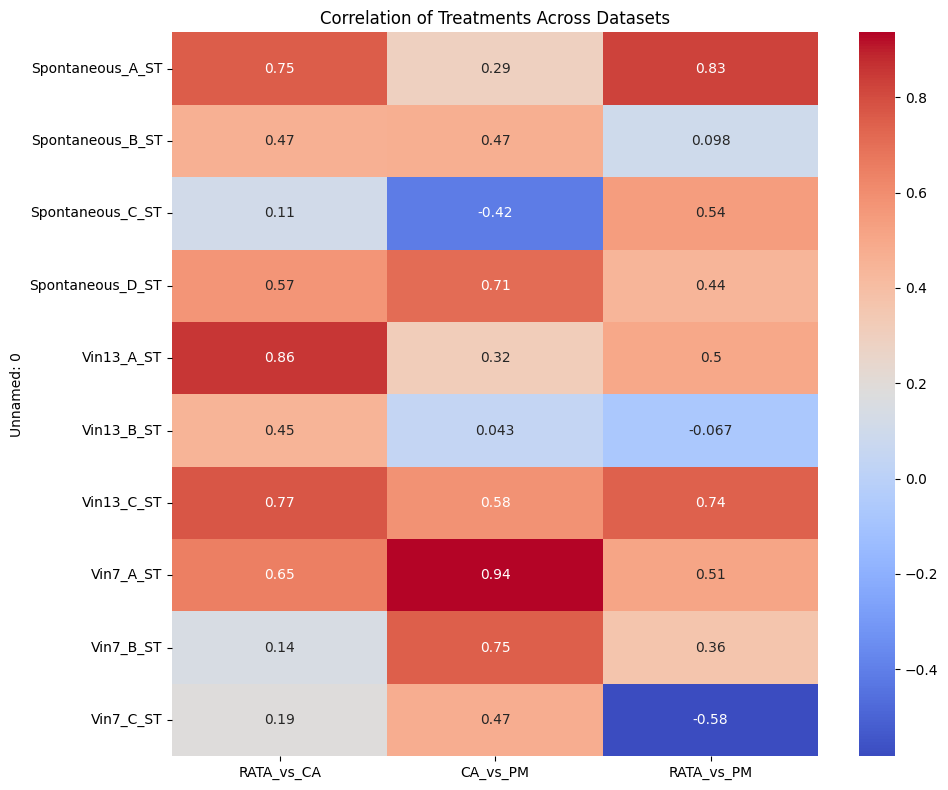

In [ ]:
# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, annot=True, cmap='coolwarm', ax=ax)
ax.set_title('Correlation of Treatments Across Datasets')
ax.set_yticklabels(treatment_names, rotation=0)

plt.tight_layout()
plt.savefig('/content/drive/My Drive/Heatmap/Output/treatment_correlations.png')
plt.show()